# Serie III · Mercado — 12. Pronóstico del precio a 1 y 3 meses

**Pregunta 3 de la prueba:** construir un modelo para pronosticar el precio del azúcar a horizontes de uno y tres
meses, con intervalos de incertidumbre; compararlo contra un modelo ingenuo con validación temporal apropiada; y
explicar las limitaciones del pronóstico y su utilidad para la planificación comercial.

**Decisiones de diseño (antes de ver resultados).**
- **Qué se pronostica.** El **precio promedio del mes** del contrato más próximo, al cierre del mes anterior. La
  planificación comercial trabaja con promedios mensuales (fijaciones, presupuesto, cotizaciones), no con el cierre de
  un día.
- **Horizontes.** Mes siguiente (h = 1) y tercer mes (h = 3). Ejemplo: al 31 de mayo se pronostica el promedio de
  junio y el de agosto.
- **Información.** Solo lo que se conoce al cierre del mes de origen. Para entrenar, solo pares cuyo resultado ya
  se conocía en ese momento.
- **Validación.** Origen rodante con ventana creciente: se entrena hasta el mes *t*, se pronostica *t+h*, se avanza un
  mes y se repite. Los orígenes van de diciembre de 2008 a 2024 (casi 9 años de historia mínima para entrenar).
- **Criterio.** Un modelo se queda solo si le gana al ingenuo con una diferencia que no sea suerte (bootstrap por
  bloques de 12 meses y prueba de Diebold-Mariano). Si no, se queda el ingenuo.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from mercado_precio import cargar_precio, markov_volatilidad, retornos
from mercado_pronostico import (mensual, pronosticos, metricas, bootstrap_pareado, diebold_mariano, bandas,
                                evaluar_bandas, MODELOS, PREDICTORES)

RAW = ROOT / "data" / "raw" / "serie3"
FIG = ROOT / "outputs" / "figures"; TAB = ROOT / "outputs" / "tables"; MOD = ROOT / "outputs" / "models"
for d in (FIG, TAB, MOD): d.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
AZUL, NARANJA, AQUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#9a9993"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
})
def guardar(fig, nombre):
    fig.tight_layout(); fig.savefig(FIG / nombre, bbox_inches="tight"); plt.show()

S = cargar_precio(RAW / "individual_data" / "Sugar_data.csv")
M = mensual(S)
print(f"{len(M)} meses completos: {M.index[0]:%m/%Y} → {M.index[-1]:%m/%Y} (junio de 2024 está incompleto y se deja fuera)")

291 meses completos: 03/2000 → 05/2024 (junio de 2024 está incompleto y se deja fuera)


## 1. El ingenuo correcto (y una trampa)

Hay dos maneras "ingenuas" de pronosticar el promedio del mes siguiente:
- **El último cierre:** el precio del último día del mes.
- **El promedio del mes:** el promedio del mes que acaba de terminar.

Parecen equivalentes, pero no lo son. Si el precio se mueve como un paseo aleatorio, el mejor pronóstico de cualquier
precio futuro es **el último precio conocido**. El promedio del mes llega "atrasado" medio mes.

Además, promediar crea un patrón artificial: los cambios entre promedios mensuales se autocorrelacionan aunque los
precios no lo hagan (en teoría ~0.25 para un paseo aleatorio; Working, 1960). Un modelo que se entrena sobre promedios
"descubre" ese patrón y parece que pronostica, pero solo está corrigiendo el atraso del promedio. El ingenuo
contra el que hay que competir es el último cierre.

In [2]:
ac_prom = M.lp.diff().autocorr(1); ac_ult = M.lu.diff().autocorr(1)
print(f"Autocorrelación de los cambios mensuales: promedios {ac_prom:.2f} · cierres de fin de mes {ac_ult:.2f}")

Autocorrelación de los cambios mensuales: promedios 0.28 · cierres de fin de mes 0.08


Los cambios entre promedios se autocorrelacionan 0.28, cerca del 0.25 teórico, y los cambios entre cierres apenas
0.08. El patrón de los promedios es casi todo artificial.

## 2. Modelos

- **Ingenuo: último cierre.** Usa el último precio. Es el estándar para precios de mercado.
- **Ingenuo: promedio del mes.** Usa el promedio del mes que terminó. Es el ingenuo "intuitivo" y sirve para mostrar
  la trampa.
- **ARIMA(1,1,0) sobre promedios.** Usa la inercia de los promedios. Es el modelo clásico de series de tiempo.
- **Regresión: momentum y reversión.** Usa el último cierre más cuatro predictores: retorno de 1 y de 12 meses,
  distancia al promedio de 5 años y forma de la curva (brecha del último cambio de contrato). Son las tres ideas con
  más respaldo en materias primas: inercia, regreso al promedio y estructura de plazos.

La regresión pronostica el **cambio** respecto del último cierre, así que si sus predictores no aportan, se reduce al
ingenuo correcto. Es la forma más justa de darle una oportunidad a la información adicional.

## 3. Validación hacia adelante

In [3]:
P = {h: pronosticos(M, h) for h in (1, 3)}
MET = {}
for h, p in P.items():
    MET[h] = metricas(p)
    print(f"h = {h} mes(es) · {len(p)} pronósticos ({p.index[0]:%m/%Y} → {p.index[-1]:%m/%Y})")
    display(MET[h].round(3))

h = 1 mes(es) · 185 pronósticos (12/2008 → 04/2024)


,MAE (¢/lb),MAPE (%),RMSE (¢/lb),sesgo (¢/lb),mejora vs último cierre (%)
Ingenuo: último cierre,0.844,4.558,1.197,0.011,0.000
Ingenuo: promedio del mes,1.111,6.110,1.553,-0.041,-31.624
"ARIMA(1,1,0) sobre promedios",1.084,6.048,1.493,0.070,-28.415
Regresión: momentum y reversión,0.860,4.648,1.211,0.072,-1.967


h = 3 mes(es) · 183 pronósticos (12/2008 → 02/2024)


,MAE (¢/lb),MAPE (%),RMSE (¢/lb),sesgo (¢/lb),mejora vs último cierre (%)
Ingenuo: último cierre,2.168,11.796,3.011,-0.082,0.000
Ingenuo: promedio del mes,2.277,12.421,3.143,-0.135,-5.022
"ARIMA(1,1,0) sobre promedios",2.344,12.933,3.260,0.206,-8.124
Regresión: momentum y reversión,2.343,12.918,3.157,0.401,-8.040


In [4]:
filas = []
for h, p in P.items():
    for m in MODELOS[1:]:
        bt = bootstrap_pareado(p, m, MODELOS[0]); dm = diebold_mariano(p, m, MODELOS[0], h)
        filas.append({"h": h, "modelo": m, "diferencia de MAE (¢/lb)": bt["dif_MAE"],
                      "IC90 bootstrap": f"{bt['IC90'][0]:+.3f} a {bt['IC90'][1]:+.3f}",
                      "P(peor que el último cierre)": bt["P(a peor)"], "DM": dm["DM"], "p (DM)": dm["p"]})
PRUEBAS = pd.DataFrame(filas)
display(PRUEBAS.round(3))

,h,modelo,diferencia de MAE (¢/lb),IC90 bootstrap,P(peor que el último cierre),DM,p (DM)
0,1,Ingenuo: promedio del mes,0.267,+0.181 a +0.371,1.000,4.915,0.000
1,1,"ARIMA(1,1,0) sobre promedios",0.240,+0.163 a +0.319,1.000,4.638,0.000
2,1,Regresión: momentum y reversión,0.017,-0.008 a +0.041,0.862,1.031,0.304
3,3,Ingenuo: promedio del mes,0.109,+0.026 a +0.182,0.986,1.855,0.065
4,3,"ARIMA(1,1,0) sobre promedios",0.176,+0.089 a +0.263,1.000,2.773,0.006
5,3,Regresión: momentum y reversión,0.174,+0.038 a +0.365,0.982,2.212,0.028


**Lectura.**
- **El último cierre gana en los dos horizontes.** A 1 mes se equivoca en promedio **0.84 ¢/lb (~5 %)**; a 3 meses,
  **2.2 ¢/lb (~12 %)**.
- **La trampa se confirma.** El ingenuo del promedio y el ARIMA sobre promedios son ~30 % peores a 1 mes, y la
  diferencia no es suerte (el intervalo del bootstrap no toca cero; Diebold-Mariano p < 0.001). Un análisis que
  hubiera comparado el ARIMA contra el ingenuo del promedio habría "encontrado" un modelo que no sirve.
- **La regresión con momentum, reversión y curva no aporta.** A 1 mes queda empatada con el último cierre (2 % peor,
  p = 0.30). A 3 meses es 8 % peor y la diferencia sí es significativa. La información adicional mete ruido de
  estimación, no señal.
- **Conclusión:** con estos datos, el precio del azúcar a 1 y 3 meses se comporta como un **paseo aleatorio**. Es lo
  esperable en un mercado de futuros líquido: lo que se puede saber hoy ya está en el precio de hoy. Coincide con la
  pregunta 2 (los ciclos de nivel no se distinguen del azar).

In [5]:
fin = P[1][MODELOS[3]].index[-1]
y = P[1].real; cols = sm.add_constant(M[PREDICTORES])
dat = pd.concat([(M.lp.shift(-1) - M.lu).rename("y"), cols], axis=1).dropna()
ols = sm.OLS(dat.y, dat.drop(columns="y")).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
print("Regresión a 1 mes con toda la muestra (errores HAC): coeficientes y p")
display(pd.DataFrame({"coef": ols.params, "p": ols.pvalues}).round(3))
print(f"R² = {ols.rsquared:.3f}")

Regresión a 1 mes con toda la muestra (errores HAC): coeficientes y p


,coef,p
const,0.005,0.271
ret_1m,0.084,0.058
ret_12m,0.006,0.686
desv_60m,-0.035,0.064
curva,-0.090,0.374


R² = 0.029


Con toda la muestra, ningún predictor es significativo al 5 %. El momentum de 1 mes y la reversión al promedio de 5
años quedan cerca (p ≈ 0.06), pero su efecto es pequeño: el R² es de 3 %. Fuera de muestra, ese efecto no alcanza
para compensar el error de estimarlo. Que no aporten no es una debilidad del modelo: es el resultado.

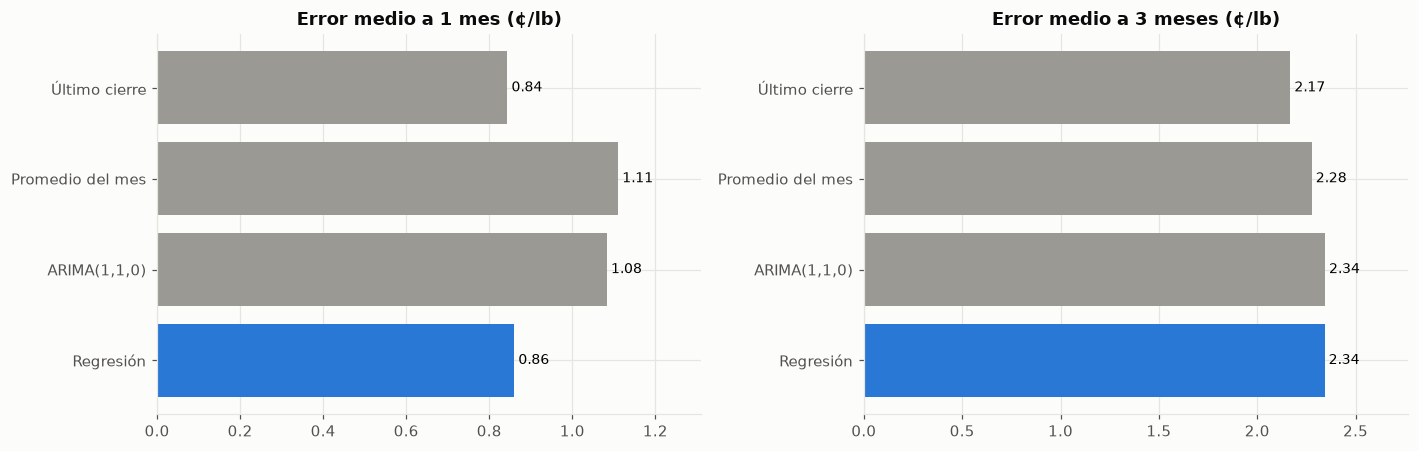

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
nom = ["Último cierre", "Promedio del mes", "ARIMA(1,1,0)", "Regresión"]
for a, h in zip(ax, (1, 3)):
    v = MET[h]["MAE (¢/lb)"].values
    a.barh(nom[::-1], v[::-1], color=[GRIS, GRIS, GRIS, AZUL][::-1])
    for i, x in enumerate(v[::-1]): a.text(x, i, f" {x:.2f}", va="center", fontsize=9)
    a.set_title(f"Error medio a {h} mes{'es' if h > 1 else ''} (¢/lb)"); a.set_xlim(0, v.max() * 1.18)
guardar(fig, "serie3_08_pronostico_errores.png")

## 4. Bandas de incertidumbre

Si el punto central no se puede mejorar, el valor está en la **banda**: cuánto se puede mover el precio. Se comparan
dos maneras de construirla, ambas con errores pasados ya realizados (sin mirar el futuro):
- **Banda fija:** los cuantiles de los errores pasados, iguales en calma y en turbulencia.
- **Banda según volatilidad:** el error se mide en unidades de la volatilidad de los últimos 3 meses. La banda se
  ensancha cuando el mercado está movido y se angosta cuando está en calma. Usa el hallazgo de la pregunta 2: el tamaño
  del movimiento sí se puede anticipar un poco, aunque la dirección no.

Una banda es buena si **cubre lo que promete** (80 % o 95 %) y es **lo más angosta posible**. La puntuación de Winkler
combina las dos cosas: el ancho más una multa por cada vez que el precio cae fuera (menor es mejor).

In [7]:
r = retornos(S).ajustado.dropna()
W, M2 = markov_volatilidad(r, 2)
alto = int(np.argmax([M2.params[f"sigma2[{i}]"] for i in range(2)]))
turb = (M2.smoothed_marginal_probabilities[alto].resample("ME").mean() > 0.5)
BAND, EVB = {}, {}
for h, p in P.items():
    for nombre, ev in [("fija", False), ("según volatilidad", True)]:
        BAND[(h, nombre)] = bandas(p, MODELOS[0], h, escala_vol=ev)
        EVB[(h, nombre)] = evaluar_bandas(BAND[(h, nombre)], turbulento=turb)
tabla = pd.concat({f"h={h} · {n}": e for (h, n), e in EVB.items()})
display(tabla.round(1))
nt = int(turb.reindex(BAND[(1, "según volatilidad")].index).fillna(False).sum())
print(f"Meses turbulentos dentro del período evaluado de las bandas: {nt} de {len(BAND[(1, 'según volatilidad')])}")

cobertura (%)  ancho medio (% del centro)  Winkler (¢/lb)  cobertura en calma (%)  cobertura en turbulencia (%)
h=1 · fija              80 %           85.2                        14.5             3.3                    85.8                          75.0
                        95 %           97.3                        25.2             5.4                    97.9                          87.5
h=1 · según volatilidad 80 %           77.9                        12.9             3.2                    77.3                          87.5
                        95 %           94.0                        21.2             5.1                    94.3                          87.5
h=3 · fija              80 %           91.0                        42.6             7.9                    91.2                          87.5
                        95 %           98.6                        69.2            11.8                    98.5                         100.0
h=3 · según volatilidad 80 %           84.1                        32.9             6.8                    83.9                          87.5
                        95 %           96.6                        48.3             9.5                    97.1                          87.5

Meses turbulentos dentro del período evaluado de las bandas: 8 de 149


**Lectura.**
- La **banda fija cubre de más**: promete 80 % y cubre 85 % a 1 mes y 91 % a 3 meses. Es demasiado ancha porque
  arrastra los errores de la turbulencia de 2009-2011 a todos los meses.
- La **banda según volatilidad** queda cerca de lo prometido (78 % y 94 % a 1 mes; 84 % y 97 % a 3 meses), es más
  angosta y tiene mejor puntuación de Winkler en los dos horizontes.
- La comparación por régimen es solo indicativa. Las bandas necesitan 3 años de errores previos, así que se evalúan
  desde 2012, y en ese período solo 8 meses son turbulentos (2016 y 2020). Con esa salvedad, la banda fija cubre de
  menos en turbulencia y de más en calma, y la banda según volatilidad reparte mejor. La ventaja principal se mide en
  el período completo.
- **Se usa la banda según volatilidad.**

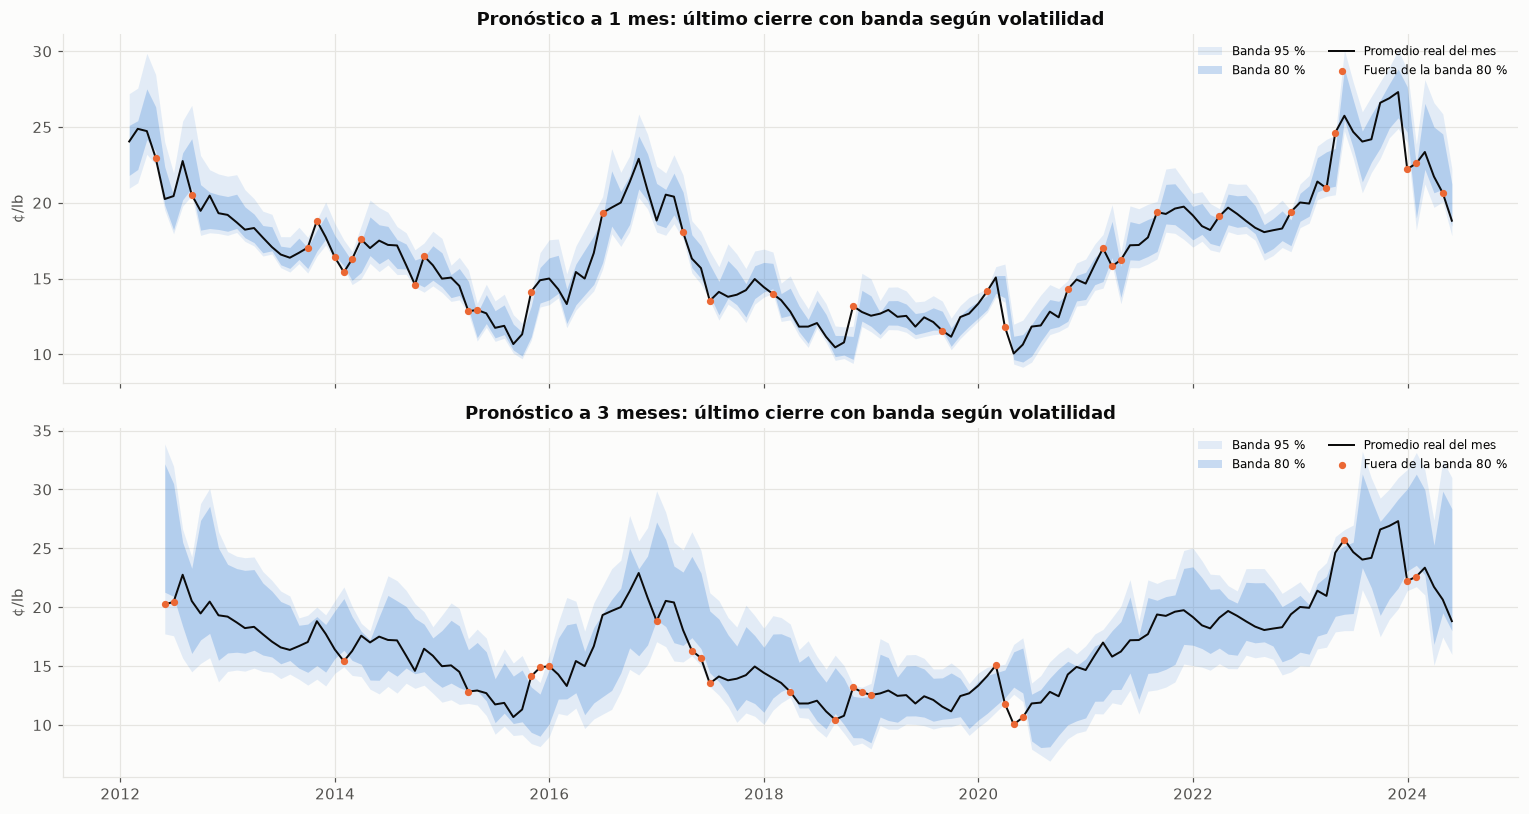

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(14, 7.5), sharex=True)
for a, h in zip(ax, (1, 3)):
    B = BAND[(h, "según volatilidad")]
    obj = P[h].loc[B.index, "objetivo"]
    a.fill_between(obj, np.exp(B.lo95), np.exp(B.hi95), color=AZUL, alpha=0.12, lw=0, label="Banda 95 %")
    a.fill_between(obj, np.exp(B.lo80), np.exp(B.hi80), color=AZUL, alpha=0.25, lw=0, label="Banda 80 %")
    a.plot(obj, np.exp(B.real), color=TINTA, lw=1.3, label="Promedio real del mes")
    fuera = (B.real < B.lo80) | (B.real > B.hi80)
    a.scatter(obj[fuera], np.exp(B.real[fuera]), color=NARANJA, s=14, zorder=3, label="Fuera de la banda 80 %")
    a.set_ylabel("¢/lb"); a.set_title(f"Pronóstico a {h} mes{'es' if h > 1 else ''}: último cierre con banda según volatilidad")
    a.legend(frameon=False, fontsize=8, loc="upper right", ncol=2)
guardar(fig, "serie3_09_pronostico_bandas.png")

## 5. El pronóstico con los datos más recientes

Con el último mes completo (mayo de 2024) se pronostica el promedio de junio (h = 1) y de agosto (h = 3). Los datos
traen junio hasta el día 24, así que el pronóstico de junio se puede revisar contra lo que ya pasó.

In [9]:
def banda_actual(p, h):
    e = (p.real - p[MODELOS[0]]) / (p.vol_3m * np.sqrt(h))
    q = np.quantile(e.dropna(), [0.025, 0.10, 0.90, 0.975])
    centro = M.lu.iloc[-1]; esc = M.vol_3m.iloc[-1] * np.sqrt(h)
    return {"centro": np.exp(centro), **{k: np.exp(centro + v * esc) for k, v in zip(["p2.5", "p10", "p90", "p97.5"], q)}}, q
VIG, QZ = {}, {}
for h in (1, 3):
    VIG[h], QZ[h] = banda_actual(P[h], h)
mes = {1: "junio 2024", 3: "agosto 2024"}
vig = pd.DataFrame({mes[h]: VIG[h] for h in (1, 3)}).T
display(vig.round(2))
junio = S.close.loc["2024-06"].mean()
print(f"Último cierre (31/05/2024): {M.ult.iloc[-1]:.2f} ¢/lb · volatilidad de 3 meses: {100 * M.vol_3m.iloc[-1]:.1f} % mensual")
print(f"Promedio real de junio hasta el 24/06: {junio:.2f} ¢/lb → dentro de la banda 80 %: {VIG[1]['p10'] <= junio <= VIG[1]['p90']}")
print(f"Cada 1 ¢/lb equivale a US${2204.62 / 100:.2f} por tonelada métrica de azúcar crudo")

,centro,p2.5,p10,p90,p97.5
junio 2024,18.3,16.70,17.23,19.58,20.42
agosto 2024,18.3,14.52,15.73,21.32,22.64


Último cierre (31/05/2024): 18.30 ¢/lb · volatilidad de 3 meses: 7.5 % mensual
Promedio real de junio hasta el 24/06: 19.05 ¢/lb → dentro de la banda 80 %: True
Cada 1 ¢/lb equivale a US$22.05 por tonelada métrica de azúcar crudo


**Cómo se lee para planificar.**
- Para junio, el punto central es el último cierre (18.3 ¢/lb), con 80 % de probabilidad de que el promedio caiga
  dentro de la banda p10-p90. El promedio real de junio (hasta el día 24) quedó dentro.
- Para agosto, la banda 80 % es mucho más ancha. Esa amplitud es la información útil: dice cuánto puede variar el
  ingreso por exportación en un trimestre si no se fija precio.
- Cada centavo por libra equivale a **US$22 por tonelada** de azúcar. En agosto, la distancia entre el centro y el
  p10 es de 2.6 ¢/lb, unos US$57 por tonelada.

In [10]:
resumen = {
    "meses": len(M), "ac_promedios": float(ac_prom), "ac_cierres": float(ac_ult),
    "metricas": {str(h): MET[h].round(4).to_dict(orient="index") for h in (1, 3)},
    "pruebas": PRUEBAS.round(4).to_dict(orient="records"),
    "regresion_full": {"coef": ols.params.round(4).to_dict(), "p": ols.pvalues.round(4).to_dict(), "r2": float(ols.rsquared)},
    "bandas": {f"{h}|{n}": e.round(3).to_dict(orient="index") for (h, n), e in EVB.items()},
    "vigente": {mes[h]: {k: round(float(v), 3) for k, v in VIG[h].items()} for h in (1, 3)},
    "junio_real_parcial": float(junio),
}
(TAB / "serie3_resumen_p3.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=1, default=str), encoding="utf-8")
modelo = {"descripcion": "Pronóstico del promedio mensual del azúcar No. 11: centro = último cierre; banda = cuantiles "
                         "de errores pasados en unidades de volatilidad de 3 meses × √h",
          "cuantiles_z": {str(h): dict(zip(["p2.5", "p10", "p90", "p97.5"], [round(float(x), 4) for x in QZ[h]])) for h in (1, 3)},
          "ultimo_cierre": float(M.ult.iloc[-1]), "vol_3m_mensual": float(M.vol_3m.iloc[-1]), "fecha_origen": f"{M.index[-1]:%Y-%m-%d}"}
(MOD / "serie3_pronostico.json").write_text(json.dumps(modelo, ensure_ascii=False, indent=1), encoding="utf-8")
for h in (1, 3):
    P[h].assign(**{c: np.exp(P[h][c]) for c in ["real", "ult"] + MODELOS}).to_csv(TAB / f"serie3_pronosticos_h{h}.csv")
print("ok")

ok


In [11]:
p1 = P[1]; e = (np.exp(p1[MODELOS[0]]) - np.exp(p1.real)).abs()
venc = p1.index.month.isin([2, 4, 6, 9])
print(f"Error del último cierre a 1 mes: {e[venc].mean():.2f} ¢/lb en orígenes de fin de feb/abr/jun/sep (el cierre es del "
      f"contrato que vence) contra {e[~venc].mean():.2f} ¢/lb en los demás ({venc.sum()} y {(~venc).sum()} orígenes)")

Error del último cierre a 1 mes: 0.89 ¢/lb en orígenes de fin de feb/abr/jun/sep (el cierre es del contrato que vence) contra 0.82 ¢/lb en los demás (62 y 123 orígenes)


## 6. Limitaciones y utilidad

**Limitaciones.**
- **Solo precio.** El modelo no ve los fundamentos que mueven el azúcar: la cosecha de Brasil, la política de
  exportación de la India, el real brasileño, el petróleo (etanol) ni el clima. Con ellos se podría intentar ganarle
  al ingenuo; sin ellos, no se pudo.
- **Un solo contrato.** El mejor pronóstico público del precio de agosto es el **precio del contrato de octubre que
  ya cotiza hoy**, que el mercado fija con toda la información disponible. La serie de la prueba solo trae el
  contrato más próximo.
- **Las bandas suponen que el pasado se repite.** Un evento sin precedentes en la muestra (por ejemplo, un cambio de
  política en la India o un choque como el de 2020) puede quedar fuera.
- **El último cierre puede ser de otro contrato que el objetivo.** Al cierre de febrero, abril, junio y septiembre, el
  último precio es el del contrato que vence ese día, y el mes objetivo ya cotiza el contrato siguiente. En esos
  orígenes el error a 1 mes es algo mayor (0.89 contra 0.82 ¢/lb). Con la curva completa se usaría directamente el
  contrato siguiente.

**Utilidad para la planificación comercial.**
- **El punto central no sirve para decidir cuándo vender:** es el precio de hoy.
- **La banda sí sirve:**
  - para presupuestar en rangos (escenarios p10, p50 y p90);
  - para dimensionar el riesgo de dejar volumen sin fijar;
  - para decidir cuánto cubrir. Cuando la volatilidad sube, la banda se ensancha y conviene fijar más.

## Evaluación gerencial

**Qué significa para el ingenio.**
- Ningún modelo basado solo en el historial del precio le gana al precio de hoy a 1 o 3 meses. El mercado ya incorpora
  lo que se sabe. Quien prometa un modelo que "adivina" el azúcar con estos datos está viendo ruido; aquí se probó y
  se descartó con pruebas formales.
- Lo que sí se puede estimar bien es **el rango**. Con la volatilidad de mayo de 2024, la banda 80 % va de −6 % a +7 % a
  1 mes y de −14 % a +17 % a 3 meses. El rango se ensancha cuando sube la volatilidad.

**Decisión recomendada.**
1. Usar el **último cierre (o la curva de futuros) como precio central** del presupuesto, con **bandas según
   volatilidad** para los escenarios.
2. Ligar la política de fijación al ancho de la banda: cuando la volatilidad sube (régimen turbulento de la pregunta
   2), aumentar el porcentaje fijado.
3. Si se quiere mejorar el punto central, el siguiente paso no es un modelo más complejo: es **agregar fundamentos**
   (avance de zafra en Brasil, política de la India, real, petróleo) y la **curva completa de futuros**.

**Impacto estimado.**
- Evita decisiones de "timing" basadas en pronósticos sin valor.
- Con bandas calibradas, el presupuesto refleja un riesgo de ~US$22/t por cada centavo de variación.

**Riesgos.**
- Eventos fuera de la muestra (cambios de política, guerras, pandemias) pueden romper la banda.
- La banda depende de la volatilidad reciente: tarda unas semanas en reaccionar al inicio de un episodio turbulento.

**Nivel de certeza.**
- **Alta:** que ninguno de los modelos probados mejora al último cierre a 1 y 3 meses (pruebas formales en ~185
  meses fuera de muestra). No haberlo superado no prueba que sea imposible: otros datos (fundamentos, curva) podrían
  lograrlo.
- **Alta:** la calibración de la banda según volatilidad a 1 mes.
- **Media:** la banda a 3 meses (menos meses independientes para evaluarla).